<a href="https://colab.research.google.com/github/GarikapatiTejaswi/natural_gas_price_analysis/blob/main/Natural_Gas_Price_Analysis_and_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as py
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import interp1d
from sklearn.linear_model import LinearRegression

In [4]:
df = pd.read_csv("/content/Nat_Gas.csv")

In [5]:
df.head()

,Dates,Prices
0,10/31/20,10.1
1,11/30/20,10.3
2,12/31/20,11.0
3,1/31/21,10.9
4,2/28/21,10.9


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Dates   48 non-null     object 
 1   Prices  48 non-null     float64
dtypes: float64(1), object(1)
memory usage: 900.0+ bytes


In [7]:
df.describe()

,Prices
count,48.000000
mean,11.207083
std,0.757897
min,9.840000
25%,10.650000
50%,11.300000
75%,11.625000
max,12.800000


In [8]:
df['Dates'] = pd.to_datetime(df['Dates'])

/tmp/ipykernel_4454/2452315616.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Dates'] = pd.to_datetime(df['Dates'])


In [9]:
df.head()

,Dates,Prices
0,2020-10-31,10.1
1,2020-11-30,10.3
2,2020-12-31,11.0
3,2021-01-31,10.9
4,2021-02-28,10.9


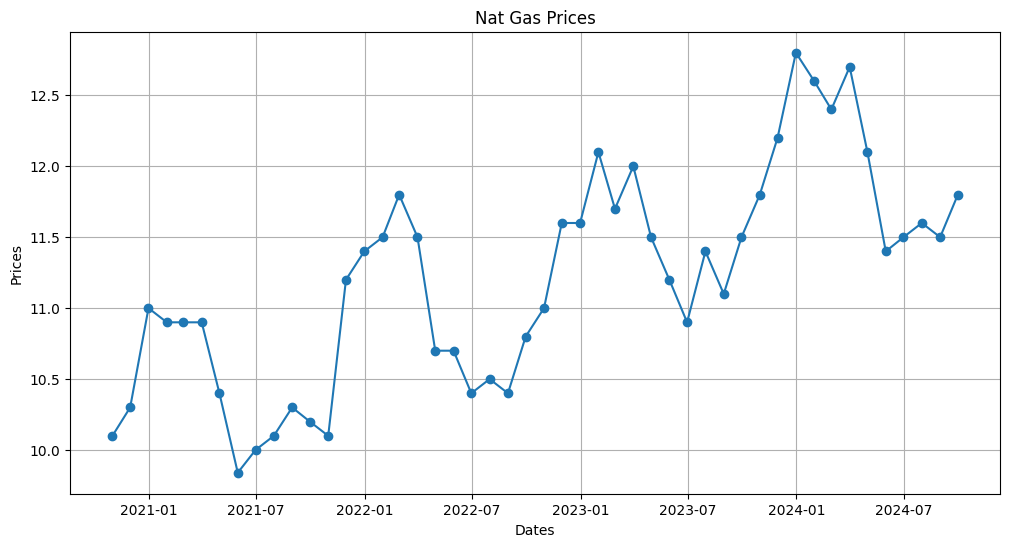

In [10]:
plt.figure(figsize=(12,6))
plt.plot(df['Dates'],df['Prices'],marker = 'o')
plt.xlabel('Dates')
plt.ylabel('Prices')
plt.title('Nat Gas Prices')
plt.grid(True)
plt.show()

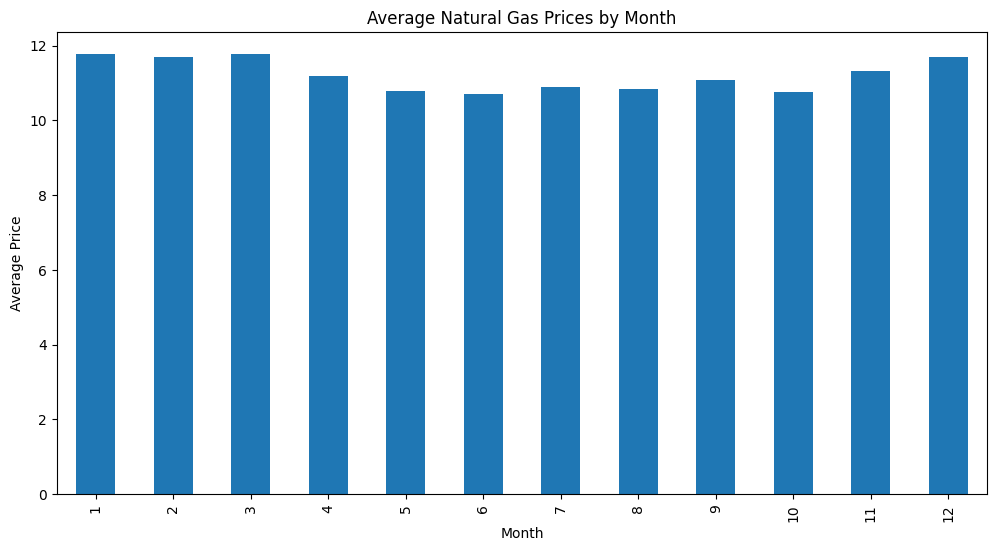

In [11]:
df['Monthly'] = df['Dates'].dt.month
monthly_avg = df.groupby('Monthly')['Prices'].mean()

monthly_avg_plot = monthly_avg.plot(kind='bar',figsize=(12,6))
monthly_avg_plot.set_xlabel('Month')
monthly_avg_plot.set_ylabel('Average Price')
monthly_avg_plot.set_title('Average Natural Gas Prices by Month')
plt.xticks(rotation=90)
plt.show()

In [12]:
x = df['Dates'].map(pd.Timestamp.timestamp)
y = df['Prices']
model = interp1d(x, y, kind="linear", fill_value="extrapolate")
def estimate_price(date):
  date = pd.Timestamp(date)
  return float(model(date.timestamp()))

In [13]:
estimate_price("2022-08-15")

10.451612903225806

In [14]:
x =df["Dates"].map(pd.Timestamp.toordinal).values.reshape(-1,1)
y = df["Prices"].values
model = LinearRegression()
model.fit(x,y)

future_dates = pd.date_range(start="2024-10-31",periods=12, freq="ME")
future_x = future_dates.map(pd.Timestamp.toordinal).values.reshape(-1,1)
future_prices =model.predict(future_x)

forecast_df = pd.DataFrame({"Date":future_dates,"Forecasted_Price":future_prices})

forecast_df

,Date,Forecasted_Price
0,2024-10-31,12.164589
1,2024-11-30,12.203060
2,2024-12-31,12.242814
3,2025-01-31,12.282567
4,2025-02-28,12.318474
5,2025-03-31,12.358227
6,2025-04-30,12.396699
7,2025-05-31,12.436452
8,2025-06-30,12.474923
9,2025-07-31,12.514677


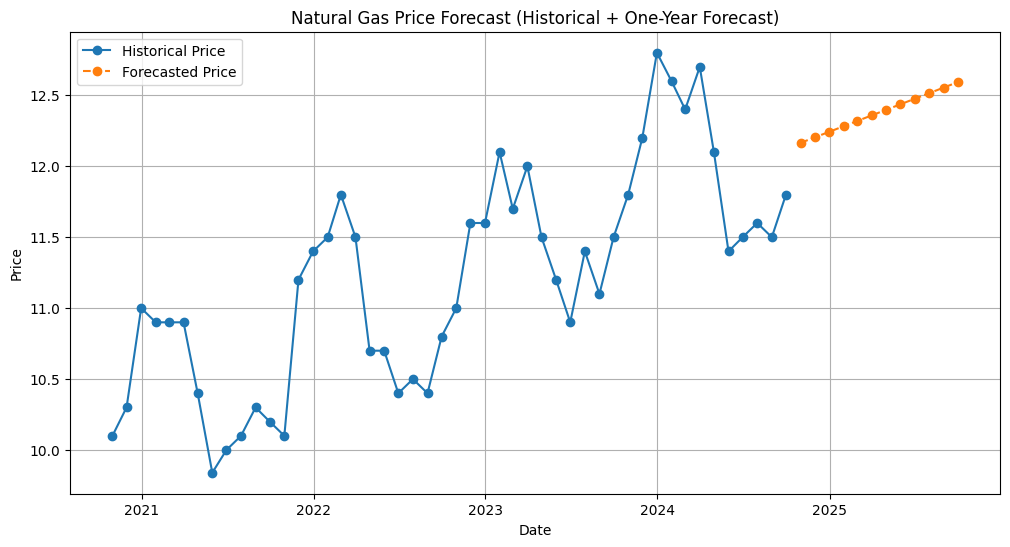

In [15]:
from matplotlib import lines
plt.figure(figsize=(12,6))
plt.plot(df['Dates'],df['Prices'],marker = 'o',label='Historical Price')

plt.plot(forecast_df['Date'],forecast_df['Forecasted_Price'],marker = 'o',label = 'Forecasted Price', linestyle = '--')
plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Natural Gas Price Forecast (Historical + One-Year Forecast)')
plt.grid(True)
plt.legend()
plt.show()

**Business Insights**

Natural gas prices climbed over time, with no signs of stopping.
Prices bounced around month to month, spiking during certain periods when demand shot up.You can estimate what prices looked like on any given day using our interpolation function.Looking ahead one year, we have got price predictions that will help you figure out storage contracts and trading moves.

**Conclusion**

We analyzed historical natural gas price data and found key trends and seasonal patterns.Built an interpolation function to estimate prices for any data in the historical record.Used a forecasting model to project prices one year beyond what we had.Visualizations show both past price movenments and whats coming next.Gives you real insights for tranding and storage decisions.You can estimate the prices evaluate long-term storage contracts, and plan your natural gas stratage with your confidence.
